# Animal Image Classification Using a CNN

The goal is to identify whether an animal image belongs to the **cat**, **dog**,
or **wild** category. A Convolutional Neural Network (CNN) learns visual patterns
from labelled images and uses those patterns to classify another image.

The complete process is:

**Image → preprocessing → learned features → class scores → predicted category**

Training teaches the model from labelled examples. Evaluation measures how well
the trained model performs on validation images. Additional evaluation checks
performance when brightness, orientation, or image detail changes.

| Training setting | Value |
|---|---|
| Input size | 256 × 256 RGB |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Weight decay | 0 |
| Batch size | 32 |
| Epochs | 15 |
| Random seed | 42 |
| Loss function | Cross-entropy |

**Running the notebook:** Open it in Google Colab, select **Runtime → Change
runtime type → GPU**, and run the cells in order. Training starts from fresh
weights. The best model is saved whenever validation accuracy improves. Tables, plots, and accuracy values are generated during execution.

Files are saved in `/content/cnn_classification_final`. Download the executed
notebook and result files before ending the Colab session.


## 1. Environment and Configuration

**What happens:** Import the required libraries and define the training settings.
PyTorch builds and trains the CNN, Torchvision prepares images, Matplotlib
displays plots, and scikit-learn calculates classification metrics. The `gdown`
utility downloads the supplied dataset.

**Why it is needed:** Keeping settings in one place makes the code easier to
understand. A GPU speeds up the large number of calculations performed during
CNN training.

A random seed controls operations such as weight initialization and image
shuffling. The value 42 is a fixed reference, not a special accuracy setting.
Fixed seeds help repeat a run, although different hardware or software versions
can still produce different results.


In [1]:
%pip -q install gdown


In [2]:
import json
import random
import zipfile
from copy import deepcopy
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0
MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]

DATASET_ID = "1PxuNRcCHmedctrmYi14pVRc02rGoUXHD"
DATA_ROOT = Path("/content/dataset/afhq")
OUTPUT_DIR = Path("/content/cnn_classification_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab before running this notebook.")

device = torch.device("cuda")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print("Device:", torch.cuda.get_device_name())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


Device: Tesla T4
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130


## 2. Dataset Preparation

**What happens:** Download and extract the AFHQ image archive if it is not already
available. The dataset contains **14,630 training images** and **1,500 validation
images**. Both splits contain `cat`, `dog`, and `wild` folders.

**Why it is needed:** Folder names provide the correct category labels. Training
images are used to update the model's weights. Validation images are used to
measure performance and select the model; they are not used for weight updates.

The supplied split is retained. A separate test set is not available in this
notebook, so the reported results are validation results.


In [3]:
if not all((DATA_ROOT / split).is_dir() for split in ["train", "val"]):
    archive_path = gdown.download(
        id=DATASET_ID,
        output="/content/afhq_dataset.zip",
        quiet=False,
    )
    if archive_path is None:
        raise RuntimeError("The dataset could not be downloaded.")
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall("/content/dataset")

if not all((DATA_ROOT / split).is_dir() for split in ["train", "val"]):
    raise FileNotFoundError("The expected AFHQ train/val directories were not found.")


Downloading...
From (original): https://drive.google.com/uc?id=1PxuNRcCHmedctrmYi14pVRc02rGoUXHD
From (redirected): https://drive.google.com/uc?id=1PxuNRcCHmedctrmYi14pVRc02rGoUXHD&confirm=t&uuid=54b49842-e4a1-4830-bfdb-e77a6ebd8d0a
To: /content/afhq_dataset.zip
100%|██████████| 730M/730M [00:18<00:00, 39.4MB/s]


## 3. Image Preprocessing and Data Inspection

**What happens:** Convert each image into the numerical format expected by the CNN.

| Step | What it does | Why it is needed |
|---|---|---|
| RGB loading | Represents an image using red, green, and blue channels | The CNN expects three input channels |
| Resize | Changes 512 × 512 images to 256 × 256 | Reduces computation and memory requirements while retaining useful visual detail |
| Tensor conversion | Converts pixels into numbers between 0 and 1 | PyTorch performs calculations on tensors |
| Normalization | Applies `(value - 0.5) / 0.5` to each channel | Centers pixel values around zero on a defined numerical scale |

All original images already have the same 512 × 512 size. Resizing is therefore
used to reduce computational cost, rather than to fix inconsistent dimensions.
A 256 × 256 image has one quarter of the pixels of a 512 × 512 image. Some fine
detail is lost during resizing; actual training speed does not necessarily
improve by the same factor.

After normalization, values lie between -1 and 1. Each input tensor has shape
**[3, 256, 256]**, meaning **[channels, height, width]**. A batch of 32 images has
shape **[32, 3, 256, 256]**.

Training, validation, and prediction use the same preprocessing so that inputs
have the same numerical meaning. Training does not apply random augmentation.

The following table checks class counts and label mapping:
**cat = 0, dog = 1, wild = 2**.


In [4]:
preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dataset = datasets.ImageFolder(DATA_ROOT / "train", transform=preprocess)
val_dataset = datasets.ImageFolder(DATA_ROOT / "val", transform=preprocess)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == {"cat": 0, "dog": 1, "wild": 2}
assert len(train_dataset) == 14630 and len(val_dataset) == 1500

class_names = train_dataset.classes
class_ids = list(range(len(class_names)))
dataset_summary = pd.DataFrame({
    "Class": class_names,
    "Training images": np.bincount(train_dataset.targets, minlength=3),
    "Validation images": np.bincount(val_dataset.targets, minlength=3),
})
display(dataset_summary)
print("Total training images:", len(train_dataset))
print("Total validation images:", len(val_dataset))
print("Class mapping:", train_dataset.class_to_idx)
dataset_summary.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)


,Class,Training images,Validation images
0,cat,5153,500
1,dog,4739,500
2,wild,4738,500


Total training images: 14630
Total validation images: 1500
Class mapping: {'cat': 0, 'dog': 1, 'wild': 2}


### Inspecting Image Samples

Display four training images from each class. This helps confirm that folder
labels match the visible content and shows differences in colour, appearance,
background, and pose.

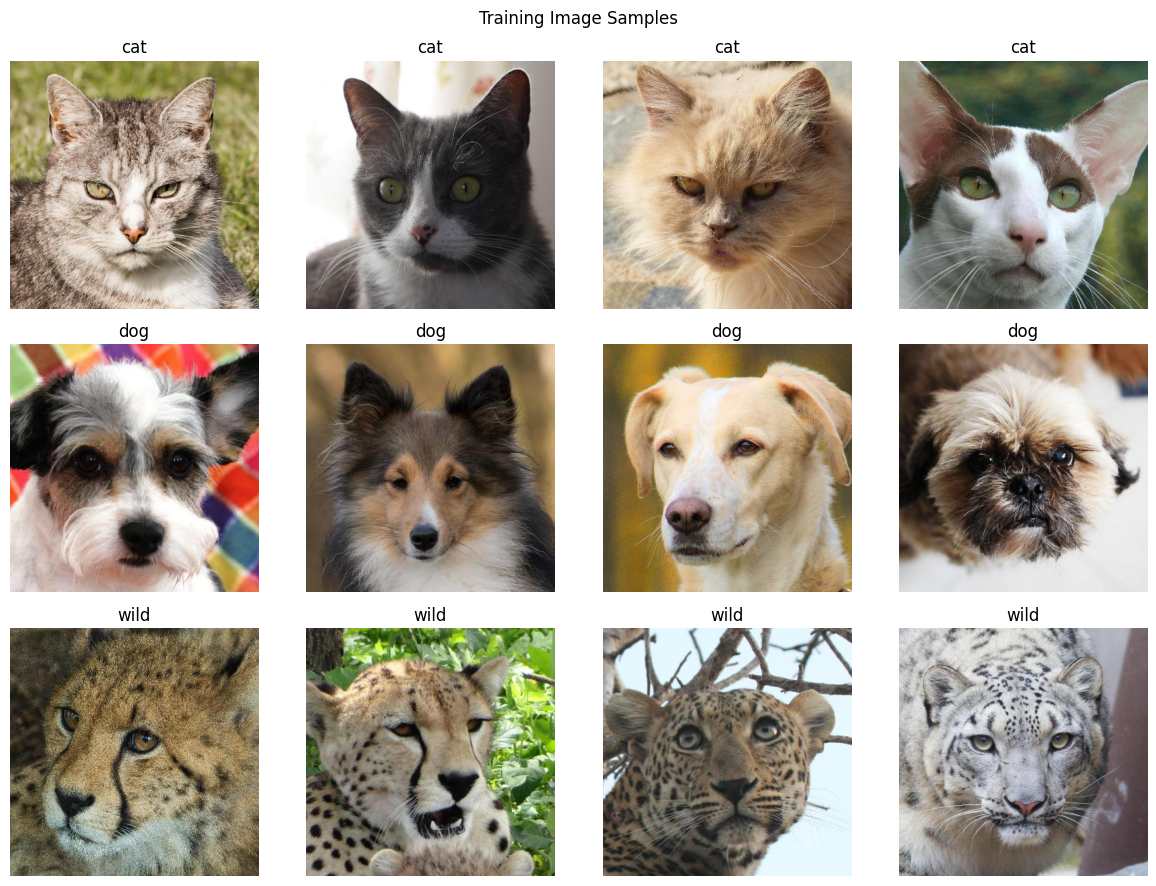

In [5]:
sample_rng = random.Random(SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for class_id, class_name in enumerate(class_names):
    indices = [
        index for index, target in enumerate(train_dataset.targets)
        if target == class_id
    ]
    for axis, index in zip(axes[class_id], sample_rng.sample(indices, 4)):
        with Image.open(train_dataset.samples[index][0]) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(class_name)
        axis.axis("off")

fig.suptitle("Training Image Samples")
plt.tight_layout()
plt.show()


### Viewing the Preprocessing Result

Display an original image beside its resized version and print the normalized
tensor's shape and value range. This connects the visible image to the numerical
input received by the CNN. The resized image is converted back to displayable
pixel values for the plot; the model still receives the normalized tensor.


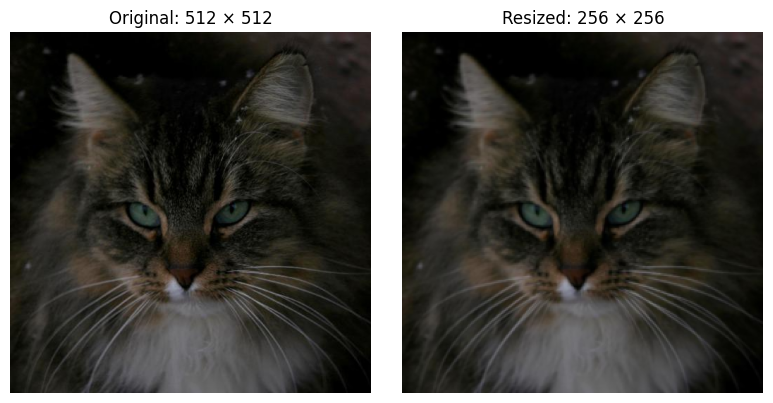

Normalized tensor shape: (3, 256, 256)
Normalized value range: [-1.000, 0.341]


In [6]:
with Image.open(train_dataset.samples[0][0]) as image:
    original_image = image.convert("RGB")

processed_image = preprocess(original_image)
display_image = (processed_image * 0.5 + 0.5).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_image)
axes[0].set_title(f"Original: {original_image.width} × {original_image.height}")
axes[1].imshow(display_image.clip(0, 1))
axes[1].set_title(f"Resized: {IMAGE_SIZE} × {IMAGE_SIZE}")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

print("Normalized tensor shape:", tuple(processed_image.shape))
print(
    "Normalized value range:",
    f"[{processed_image.min().item():.3f}, {processed_image.max().item():.3f}]",
)


## 4. CNN Architecture and Initialization

**What happens:** Build a CNN with a feature extractor and a classifier.
The feature extractor learns patterns from images. The classifier uses those
patterns to produce a score for each category.

| Component | Simple explanation | Purpose |
|---|---|---|
| Convolution | Slides small learned filters across an image or feature map | Finds useful local patterns |
| ReLU | Replaces negative values with zero | Adds a nonlinear operation so the model can learn complex relationships |
| Max pooling | Keeps the largest response in each small region | Reduces spatial size and computation |
| Adaptive average pooling | Summarizes each final feature map into a 4 × 4 grid | Produces a fixed-size representation for the classifier |
| Flatten | Converts the feature grids into one list of numbers | Prepares features for fully connected layers |
| Fully connected layers | Combine the extracted features | Produce three class scores |

**Feature sizes:** The three convolution-and-pooling blocks produce
**32 × 128 × 128**, **64 × 64 × 64**, and **128 × 32 × 32** tensors.
More channels allow different learned responses while pooling reduces spatial
detail. Adaptive pooling produces **128 × 4 × 4 = 2,048** values for the classifier.

The final output contains three raw scores called **logits**. A batch of 32
images produces an output of shape **[32, 3]**. The largest score determines
the predicted class. Softmax is only needed to display normalized class scores.

**Why it is needed:** Useful image features are learned from examples instead
of being manually defined. Early layers can respond to edges or textures;
later layers can combine responses into more complex patterns.

Weights are initialized randomly using the fixed seed. The data loaders supply
32 images at a time. Training images are shuffled each epoch; validation images
retain a fixed order so predictions can be matched to their filenames.


In [7]:
class AnimalCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 3),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model = AnimalCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

train_generator = torch.Generator().manual_seed(SEED)
val_generator = torch.Generator().manual_seed(SEED + 1)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=False, generator=train_generator,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=False, generator=val_generator,
)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


AnimalCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=2048, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
Trainable parameters: 355907


## 5. Training and Validation

**What happens:** Train the CNN for 15 epochs. One epoch is one complete pass
through the training set.

Each training batch follows these steps:

1. Pass images through the CNN to obtain class scores.
2. Compare those scores with the correct labels using cross-entropy loss.
3. Calculate gradients, which describe how the loss changes with each weight.
4. Let Adam update the weights using those gradients.
5. Clear the previous gradients before processing the next batch.

**Why it is needed:** Repeated updates allow the model to learn useful patterns
from labelled examples. Lower training loss means a better fit to the training
data, but it does not automatically mean better performance on other images.

Adam uses gradient history to adapt updates for different weights. The learning
rate **0.001** controls the update scale. **Weight decay 0** means no additional
weight-decay penalty is applied. Cross-entropy receives raw logits directly;
applying softmax before this loss is unnecessary.

After each epoch, validation measures loss and accuracy without updating any
weights. Loss is averaged over images, and accuracy is the percentage of correct
predictions. The highest-validation-accuracy model is retained in memory and saved to
`best_animal_cnn.pth` whenever accuracy improves.
If two epochs have the same accuracy, the earlier epoch is retained.

The code below first defines the training and evaluation functions, then runs
the full training loop. Running initialization and training again starts fresh.


In [8]:
def train_one_epoch(model, loader, optimizer, criterion, device, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(loader, desc=f"Epoch {epoch}/{EPOCHS}"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    targets, predictions = [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        targets.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(dim=1).cpu().tolist())

    targets = np.asarray(targets)
    predictions = np.asarray(predictions)
    return {
        "loss": total_loss / len(targets),
        "accuracy": 100.0 * float(np.mean(targets == predictions)),
        "targets": targets,
        "predictions": predictions,
    }


### Running the Training Loop

Each output line reports training and validation loss and accuracy for one epoch.
The selected epoch is the one with the highest validation accuracy, which may
differ from the final epoch. Training still completes all 15 epochs.

**Best-model checkpointing:** After each epoch, validation accuracy is compared
with the best value seen so far. A strictly higher accuracy updates the saved
checkpoint. Equal or lower accuracy keeps the previous checkpoint, so the saved
model is not necessarily the model from the final epoch.

The checkpoint contains learned weights, the selected epoch, validation accuracy
and loss, class labels, preprocessing settings, and training settings. It is saved
inside the training loop; reaching the final notebook section is not required.
Only the current best checkpoint is kept, rather than a separate file for every epoch.


In [9]:
history = []
best_accuracy = -1.0
best_epoch = 0
best_model = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, optimizer, criterion, device, epoch
    )
    validation = evaluate_model(model, val_loader, criterion, device)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": validation["loss"],
        "validation_accuracy": validation["accuracy"],
    })

    if validation["accuracy"] > best_accuracy:
        best_accuracy = validation["accuracy"]
        best_epoch = epoch
        best_model = deepcopy(model).cpu()

        torch.save(
            {
                "model_state_dict": best_model.state_dict(),
                "epoch": best_epoch,
                "validation_accuracy": best_accuracy,
                "validation_loss": validation["loss"],
                "class_to_idx": train_dataset.class_to_idx,
                "image_size": IMAGE_SIZE,
                "mean": MEAN,
                "std": STD,
                "architecture": str(best_model),
                "optimizer": "Adam",
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "seed": SEED,
                "batch_size": BATCH_SIZE,
            },
            OUTPUT_DIR / "best_animal_cnn.pth",
        )
        print(f"Best-model checkpoint saved at epoch {best_epoch}.")

    print(
        f"Train loss: {train_loss:.4f} | Train accuracy: {train_accuracy:.2f}% | "
        f"Validation loss: {validation['loss']:.4f} | "
        f"Validation accuracy: {validation['accuracy']:.2f}%"
    )

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
evaluation_model = best_model.to(device)
evaluation_model.eval()
print(f"Selected epoch: {best_epoch} | Validation accuracy: {best_accuracy:.2f}%")


Epoch 1/15:   0%|          | 0/458 [00:00<?, ?it/s]

Best-model checkpoint saved at epoch 1.
Train loss: 0.5154 | Train accuracy: 78.16% | Validation loss: 0.2750 | Validation accuracy: 89.87%


Epoch 2/15:   0%|          | 0/458 [00:00<?, ?it/s]

Best-model checkpoint saved at epoch 2.
Train loss: 0.2173 | Train accuracy: 91.85% | Validation loss: 0.2102 | Validation accuracy: 92.13%


Epoch 3/15:   0%|          | 0/458 [00:00<?, ?it/s]

Best-model checkpoint saved at epoch 3.
Train loss: 0.1553 | Train accuracy: 94.25% | Validation loss: 0.1448 | Validation accuracy: 95.00%


... (20 outputs left out)

Epoch 14/15:   0%|          | 0/458 [00:00<?, ?it/s]

Train loss: 0.0244 | Train accuracy: 99.06% | Validation loss: 0.0802 | Validation accuracy: 98.20%


Epoch 15/15:   0%|          | 0/458 [00:00<?, ?it/s]

Best-model checkpoint saved at epoch 15.
Train loss: 0.0218 | Train accuracy: 99.19% | Validation loss: 0.0725 | Validation accuracy: 98.73%
Selected epoch: 15 | Validation accuracy: 98.73%


## 6. Learning Curves

**What happens:** Plot training and validation loss and accuracy after every epoch.

**Why it is needed:** Curves show whether learning progresses smoothly and whether
improvements on training images also appear on validation images.

- **Falling loss:** The model's scores fit the correct labels better on that split.
- **Rising accuracy:** A larger proportion of images receive the correct category.
- **Training improves while validation worsens:** This can be a sign of overfitting,
  where the model fits training details that do not transfer well.
- **Validation moves up and down:** Performance fluctuates; one spike alone does
  not identify the cause.

Loss and accuracy measure different things. Accuracy only checks the winning
class, while cross-entropy also considers the score assigned to the correct
class.


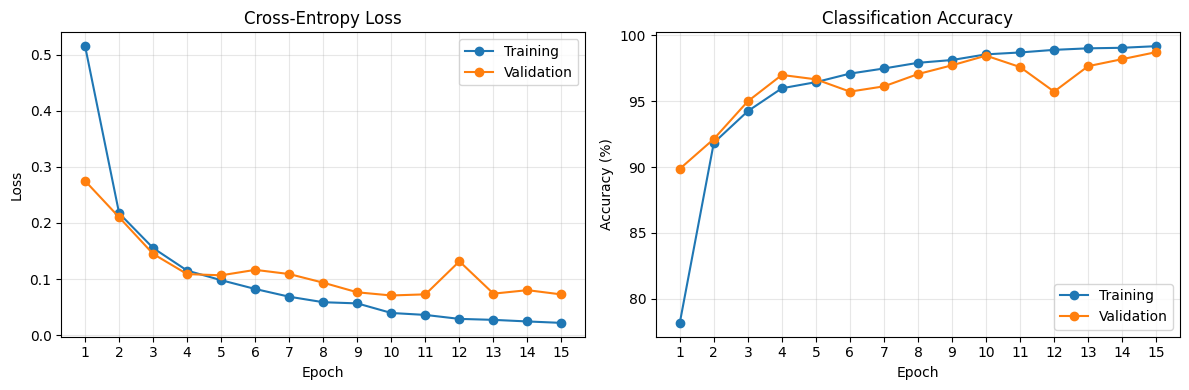

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], "o-", label="Training")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], "o-", label="Validation")
axes[0].set(title="Cross-Entropy Loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(history_df["epoch"], history_df["train_accuracy"], "o-", label="Training")
axes[1].plot(history_df["epoch"], history_df["validation_accuracy"], "o-", label="Validation")
axes[1].set(title="Classification Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
for axis in axes:
    axis.set_xticks(range(1, EPOCHS + 1))
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Validation Performance

**What happens:** Evaluate the selected model on all 1,500 validation images and
calculate overall and per-class metrics.

| Metric | Simple meaning |
|---|---|
| Accuracy | Percentage of all images classified correctly |
| Precision | Of the images predicted as a class, how many actually belong to it |
| Recall | Of the images that actually belong to a class, how many were identified correctly |
| F1-score | A combined measure of precision and recall |
| Support | Number of actual images in each class |

**Why it is needed:** Overall accuracy can hide differences between categories.
The classification report shows performance for each class, and the confusion
matrix shows exactly which categories are confused.

In the confusion matrix, **rows are actual labels** and **columns are predicted
labels**. Diagonal entries are correct predictions. An entry in the `wild` row
and `dog` column counts wild animals incorrectly predicted as dogs.

These images are held out from weight updates, but validation also selects the
model.

Validation accuracy: 98.73%
Validation loss: 0.0725
Incorrect predictions: 19/1500
              precision    recall  f1-score   support

         cat     0.9900    0.9920    0.9910       500
         dog     0.9783    0.9940    0.9861       500
        wild     0.9939    0.9760    0.9849       500

    accuracy                         0.9873      1500
   macro avg     0.9874    0.9873    0.9873      1500
weighted avg     0.9874    0.9873    0.9873      1500



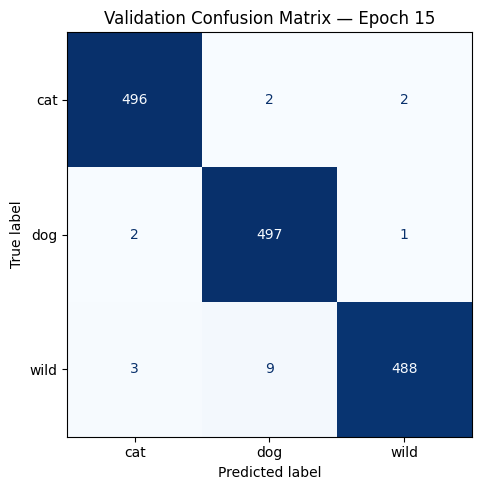

In [12]:
validation_results = evaluate_model(evaluation_model, val_loader, criterion, device)
y_true = validation_results["targets"]
y_pred = validation_results["predictions"]
total_errors = int(np.sum(y_true != y_pred))

print(f"Validation accuracy: {validation_results['accuracy']:.2f}%")
print(f"Validation loss: {validation_results['loss']:.4f}")
print(f"Incorrect predictions: {total_errors}/{len(y_true)}")
print(classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0,
))

report = classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / "classification_report.csv")

matrix = confusion_matrix(y_true, y_pred, labels=class_ids)
fig, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=axis, cmap="Blues", values_format="d", colorbar=False,
)
axis.set_title(f"Validation Confusion Matrix — Epoch {best_epoch}")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

pd.DataFrame({
    "image_path": [path for path, _ in val_dataset.samples],
    "actual_class": [class_names[label] for label in y_true],
    "predicted_class": [class_names[label] for label in y_pred],
    "correct": y_true == y_pred,
}).to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)


## 8. Visualizing Learned Features

**What happens:** Pass a validation image through the trained CNN and display
six feature maps after the ReLU operation in each convolutional block.
The image in the first column is the original input for every row.

**Why it is needed:** This makes the feature-extraction stage visible. A feature
map records how strongly one learned filter responds at different image positions.
Brighter areas indicate stronger responses within the displayed map.

The printed shapes show how the internal representation changes through the
network. Different channels can respond to different patterns, but the maps do
not come with labels such as "eye" or "ear". A visible response is not proof
that a filter detects a specific animal part.

These are activations of the trained network, not additional training data or
manually designed image features.


Block 1 activation shape: (32, 256, 256)
Block 2 activation shape: (64, 128, 128)
Block 3 activation shape: (128, 64, 64)


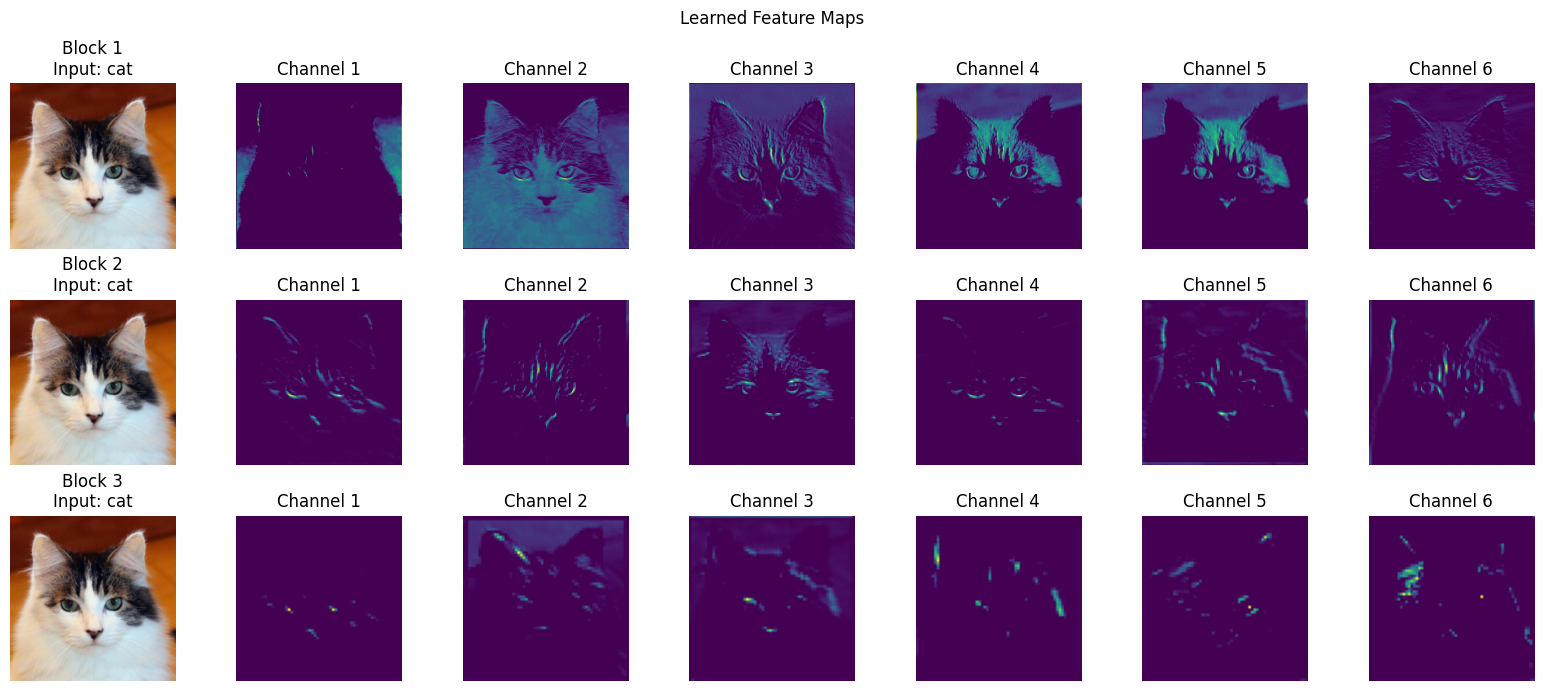

In [13]:
feature_image, feature_label = val_dataset[0]
activation_maps = []

evaluation_model.eval()
with torch.no_grad():
    features = feature_image.unsqueeze(0).to(device)
    for layer in evaluation_model.features:
        features = layer(features)
        if isinstance(layer, nn.ReLU):
            activation_maps.append(features[0].cpu())

fig, axes = plt.subplots(3, 7, figsize=(16, 7))
input_display = (feature_image * 0.5 + 0.5).permute(1, 2, 0).numpy().clip(0, 1)
for row, activations in enumerate(activation_maps):
    axes[row, 0].imshow(input_display)
    axes[row, 0].set_title(f"Block {row + 1}\nInput: {class_names[feature_label]}")
    for channel in range(6):
        axes[row, channel + 1].imshow(activations[channel], cmap="viridis")
        axes[row, channel + 1].set_title(f"Channel {channel + 1}")
    print(f"Block {row + 1} activation shape:", tuple(activations.shape))
for axis in axes.flat:
    axis.axis("off")
fig.suptitle("Learned Feature Maps")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_maps.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Example Predictions

**What happens:** Display sample validation images with their actual and predicted
categories. The first row shows correct predictions. The second row shows
incorrect predictions when errors are available.

**Why it is needed:** Images make the numerical results easier to interpret.
Incorrect examples reveal cases that remain difficult, such as animals with
similar appearances. The examples illustrate individual outcomes; the metrics
above summarize the full validation set.

Green titles indicate correct predictions. Red titles indicate mistakes.
A fixed sampling seed makes the examples repeatable for a given set of results.


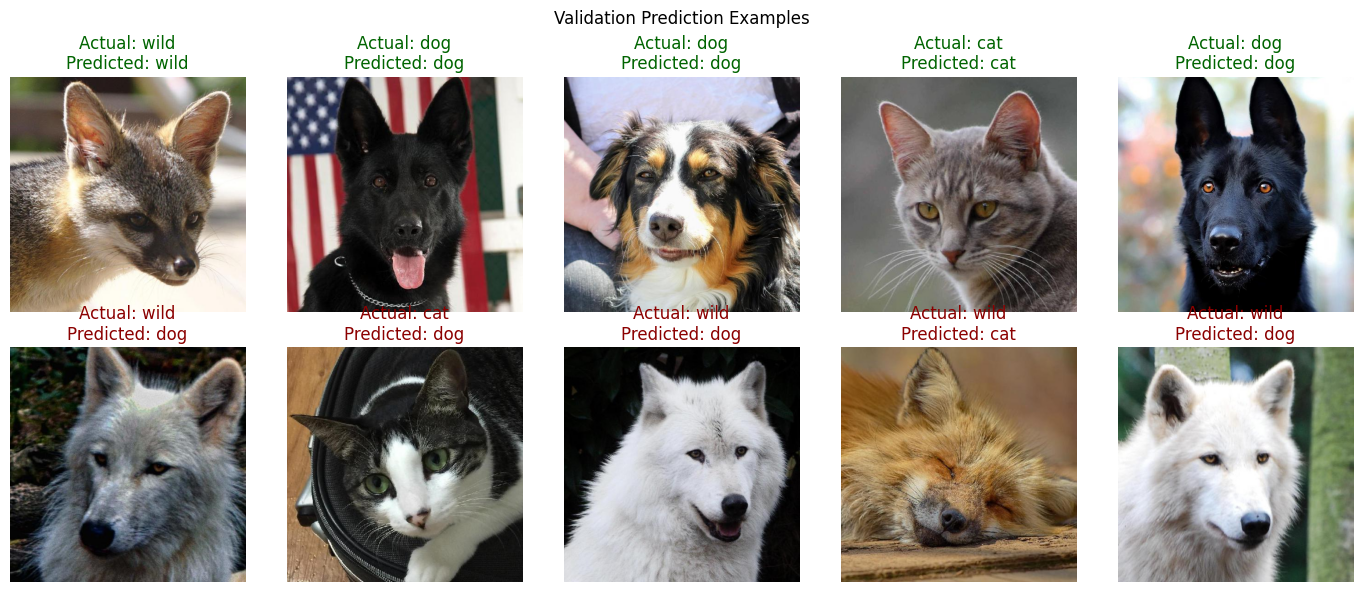

In [14]:
prediction_rng = np.random.default_rng(SEED)
groups = [np.flatnonzero(y_true == y_pred), np.flatnonzero(y_true != y_pred)]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for row, indices in enumerate(groups):
    selected = prediction_rng.choice(indices, size=min(5, len(indices)), replace=False)
    for column, axis in enumerate(axes[row]):
        axis.axis("off")
        if column >= len(selected):
            continue
        index = int(selected[column])
        with Image.open(val_dataset.samples[index][0]) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(
            f"Actual: {class_names[y_true[index]]}\nPredicted: {class_names[y_pred[index]]}",
            color="darkgreen" if row == 0 else "darkred",
        )

fig.suptitle("Validation Prediction Examples")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "prediction_examples.png", dpi=160, bbox_inches="tight")
plt.show()


## 10. Performance on Image Variations

**What happens:** Evaluate the same trained model on modified copies of all 1,500
validation images. Only one modification is applied at a time, followed by the
standard preprocessing. The correct category remains unchanged.

| Image condition | What changes | What it checks |
|---|---|---|
| Original | No additional modification | Reference performance |
| Darker | Brightness is multiplied by 0.6 | Sensitivity to reduced brightness |
| Brighter | Brightness is multiplied by 1.4 | Sensitivity to increased brightness |
| Horizontal flip | The image is reflected left to right | Sensitivity to left-right orientation |
| Rotation | The image is rotated by 15 degrees | Sensitivity to a small tilt |
| Reduced detail | The image is reduced to 64 × 64 before standard resizing | Sensitivity to lost fine detail |

**Why it is needed:** A useful classifier should handle reasonable changes in
appearance. Measuring accuracy under these conditions shows which changes the
model handles well and which ones reduce its performance.

The preview shows what each change looks like. The table reports results on the
entire validation set, not just the preview image. **Accuracy change** is the
modified-image accuracy minus the original-image accuracy, in percentage points.
A negative value means performance decreased.

No weights are updated and the selected model is not changed during these checks.
The results provide evidence for the specific conditions evaluated; they do not
guarantee reliable predictions under every possible real-world condition.


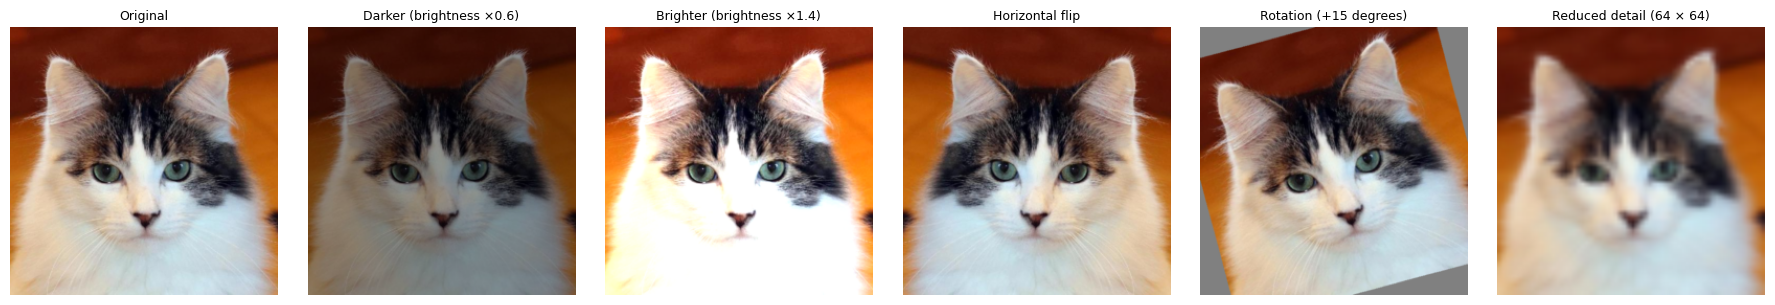

In [15]:
variation_functions = {
    "Original": lambda image: image,
    "Darker (brightness ×0.6)": lambda image: TF.adjust_brightness(image, 0.6),
    "Brighter (brightness ×1.4)": lambda image: TF.adjust_brightness(image, 1.4),
    "Horizontal flip": lambda image: TF.hflip(image),
    "Rotation (+15 degrees)": lambda image: TF.rotate(
        image, angle=15, interpolation=InterpolationMode.BILINEAR,
        fill=(128, 128, 128),
    ),
    "Reduced detail (64 × 64)": lambda image: TF.resize(image, [64, 64]),
}

with Image.open(val_dataset.samples[0][0]) as image:
    variation_example = image.convert("RGB")

fig, axes = plt.subplots(1, len(variation_functions), figsize=(18, 3))
for axis, (name, variation) in zip(axes, variation_functions.items()):
    image_tensor = preprocess(variation(variation_example))
    axis.imshow((image_tensor * 0.5 + 0.5).permute(1, 2, 0).numpy().clip(0, 1))
    axis.set_title(name, fontsize=9)
    axis.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "image_variations.png", dpi=160, bbox_inches="tight")
plt.show()


Evaluating image variations:   0%|          | 0/6 [00:00<?, ?it/s]

,Condition,Accuracy (%),Loss,Errors,Accuracy change (percentage points)
0,Original,98.7333,0.0725,19,0.0000
1,Darker (brightness ×0.6),94.9333,0.1880,76,-3.8000
2,Brighter (brightness ×1.4),98.2000,0.0996,27,-0.5333
3,Horizontal flip,98.2000,0.0711,27,-0.5333
4,Rotation (+15 degrees),95.2667,0.2449,71,-3.4667
5,Reduced detail (64 × 64),78.8667,0.7433,317,-19.8667


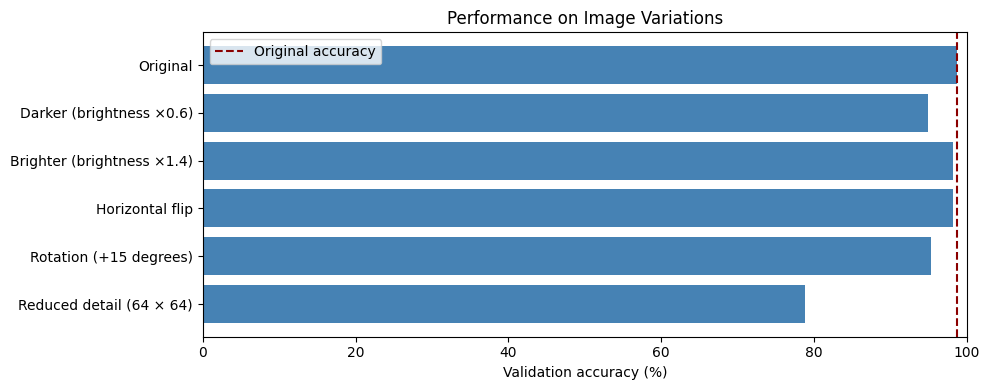

In [16]:
variation_rows = []

for name, variation in tqdm(variation_functions.items(), desc="Evaluating image variations"):
    if name == "Original":
        result = validation_results
    else:
        variation_dataset = datasets.ImageFolder(
            DATA_ROOT / "val",
            transform=transforms.Compose([variation, preprocess]),
        )
        assert variation_dataset.samples == val_dataset.samples
        variation_loader = DataLoader(
            variation_dataset, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=0, pin_memory=False,
        )
        result = evaluate_model(evaluation_model, variation_loader, criterion, device)

    variation_rows.append({
        "Condition": name,
        "Accuracy (%)": result["accuracy"],
        "Loss": result["loss"],
        "Errors": int(np.sum(result["targets"] != result["predictions"])),
        "Accuracy change (percentage points)": result["accuracy"] - validation_results["accuracy"],
    })

variation_df = pd.DataFrame(variation_rows)
display(variation_df.round(4))
variation_df.to_csv(OUTPUT_DIR / "image_variation_metrics.csv", index=False)

fig, axis = plt.subplots(figsize=(10, 4))
axis.barh(variation_df["Condition"], variation_df["Accuracy (%)"], color="steelblue")
axis.axvline(validation_results["accuracy"], color="darkred", linestyle="--", label="Original accuracy")
axis.set(xlim=(0, 100), xlabel="Validation accuracy (%)", title="Performance on Image Variations")
axis.invert_yaxis()
axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "image_variation_accuracy.png", dpi=160, bbox_inches="tight")
plt.show()


## 11. Single-Image Prediction

**What happens:** Accept an image path, convert the image to RGB, apply the same
preprocessing, and pass it through the selected model. Softmax converts the
three logits into scores that sum to one. The class with the highest score is
returned as the prediction.

**Why it is needed:** This demonstrates how the trained classifier can be used for one image after training, rather than only evaluating an entire dataset.

The example uses a validation image that was not used for weight updates.
To demonstrate an external image, upload an animal image through the Colab Files panel and replace `image_path` with its path. No retraining is required.

The model chooses `cat`, `dog`, or `wild`, it does not have an "unknown" category.

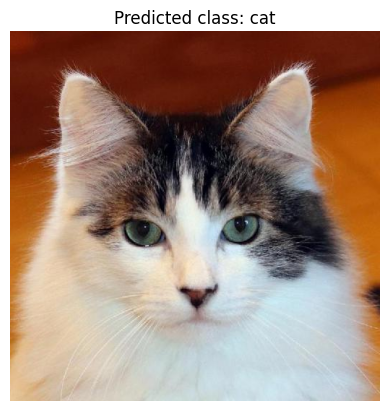

,Class,Softmax score (%)
0,cat,100.0
1,dog,0.0
2,wild,0.0


In [17]:
@torch.no_grad()
def predict_image(image_path, model, transform, class_names, device):
    with Image.open(image_path) as image:
        image_tensor = transform(image.convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    scores = torch.softmax(model(image_tensor), dim=1)[0].cpu()
    predicted_id = int(scores.argmax().item())
    return class_names[predicted_id], {
        name: float(scores[index].item())
        for index, name in enumerate(class_names)
    }


image_path = Path(val_dataset.samples[0][0])
predicted_class, class_scores = predict_image(
    image_path, evaluation_model, preprocess, class_names, device
)

with Image.open(image_path) as image:
    plt.imshow(image.convert("RGB"))
plt.title(f"Predicted class: {predicted_class}")
plt.axis("off")
plt.show()
display(pd.DataFrame({
    "Class": list(class_scores),
    "Softmax score (%)": [100 * score for score in class_scores.values()],
}).round(2))


## 12. Save the Trained Model and Results

**What happens:** Save the selected model's learned weights, class mapping, input
size, and normalization values. Save the training history, evaluation tables,
predictions, plots, and a summary of the completed run.

**Why it is needed:** Model weights are needed for future prediction. Class
mapping explains what each output index means, and preprocessing settings help
keep future inputs consistent with training. Saved reports document the results.

The printed summary includes the selected epoch, validation accuracy, error
count, and the image modification with the lowest accuracy. Interpret reliability
from these measured results. The summary is calculated during execution rather
than filled with an assumed accuracy value.

The output directory is local to the Colab runtime.

**Model files:**

- `best_animal_cnn.pth` is updated during training whenever validation accuracy improves.
- `animal_cnn.pth` is the final inference export of the same selected model.

Both files contain the selected model's weights and metadata. The architecture
must match when the weights are used for prediction. Neither file contains an
optimizer state for resuming training.

All files are saved locally in Colab.


In [18]:
torch.save({
    "model_state_dict": {
        name: parameter.detach().cpu()
        for name, parameter in evaluation_model.state_dict().items()
    },
    "class_to_idx": train_dataset.class_to_idx,
    "image_size": IMAGE_SIZE,
    "mean": MEAN,
    "std": STD,
    "selected_epoch": best_epoch,
    "validation_accuracy": validation_results["accuracy"],
    "architecture": str(evaluation_model),
}, OUTPUT_DIR / "animal_cnn.pth")

lowest_variation = variation_df.iloc[1:].sort_values("Accuracy (%)").iloc[0]
summary = {
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "selected_epoch": best_epoch,
    "training_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "validation_accuracy": validation_results["accuracy"],
    "validation_loss": validation_results["loss"],
    "validation_errors": total_errors,
    "lowest_accuracy_variation": str(lowest_variation["Condition"]),
    "lowest_variation_accuracy": float(lowest_variation["Accuracy (%)"]),
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "gpu": torch.cuda.get_device_name(),
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print(f"Selected epoch: {best_epoch}/{EPOCHS}")
print(f"Original validation accuracy: {validation_results['accuracy']:.2f}%")
print(f"Original validation errors: {total_errors}/{len(val_dataset)}")
print(
    f"Lowest accuracy among modified conditions: {lowest_variation['Condition']} "
    f"({lowest_variation['Accuracy (%)']:.2f}%; "
    f"change {lowest_variation['Accuracy change (percentage points)']:+.2f} percentage points)"
)
print("Results directory:", OUTPUT_DIR)
print("These results describe validation performance and the specific variations evaluated.")


Selected epoch: 15/15
Original validation accuracy: 98.73%
Original validation errors: 19/1500
Lowest accuracy among modified conditions: Reduced detail (64 × 64) (78.87%; change -19.87 percentage points)
Results directory: /content/cnn_classification_final
These results describe validation performance and the specific variations evaluated.
